# 01 — Eksplorasi Data Harga Pangan PIHPS

Notebook ini menjawab F-03: tren, dekomposisi musiman (STL), ACF/PACF, dan efek hari raya. Data: `data/processed/prices.parquet` (hasil `make data`).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
from src.clean import load_prices, get_series
from src.config import load_config
cfg = load_config()
LABEL = {k: v["label"] for k, v in cfg["commodities"].items()}
prices = load_prices()
prices.groupby(["region", "commodity"]).agg(mulai=("date", "min"), akhir=("date", "max"), n=("price", "size"),
    imputasi_pct=("is_imputed", lambda s: 100 * s.mean()), harga_rata2=("price", "mean"))

mulai      akhir     n  imputasi_pct  \
region   commodity                                                        
diy      bawang_merah         2018-01-02 2026-09-24  3188         30.87   
         bawang_putih         2018-01-02 2026-09-24  3188         30.87   
         beras_medium_1       2018-01-02 2026-09-24  3188         30.87   
         cabai_merah_keriting 2018-01-02 2026-09-24  3188         30.90   
         cabai_rawit_merah    2018-01-02 2026-09-24  3188         30.87   
nasional bawang_merah         2018-01-01 2026-09-24  3189         29.16   
         bawang_putih         2018-01-01 2026-09-24  3189         29.19   
         beras_medium_1       2018-01-01 2026-09-24  3189         29.07   
         cabai_merah_keriting 2018-01-01 2026-09-24  3189         29.35   
         cabai_rawit_merah    2018-01-01 2026-09-24  3189         29.44   

                               harga_rata2  
region   commodity                          
diy      bawang_merah            33,477.38  
         bawang_putih            35,213.30  
         beras_medium_1          13,042.00  
         cabai_merah_keriting    37,238.88  
         cabai_rawit_merah       44,674.42  
nasional bawang_merah            37,425.51  
         bawang_putih            35,190.15  
         beras_medium_1          13,293.31  
         cabai_merah_keriting    45,779.35  
         cabai_rawit_merah       57,221.47

## 1. Tren harga

Rata-rata mingguan, satu panel per komoditas (skala berbeda sehingga tidak digabung dalam satu sumbu).

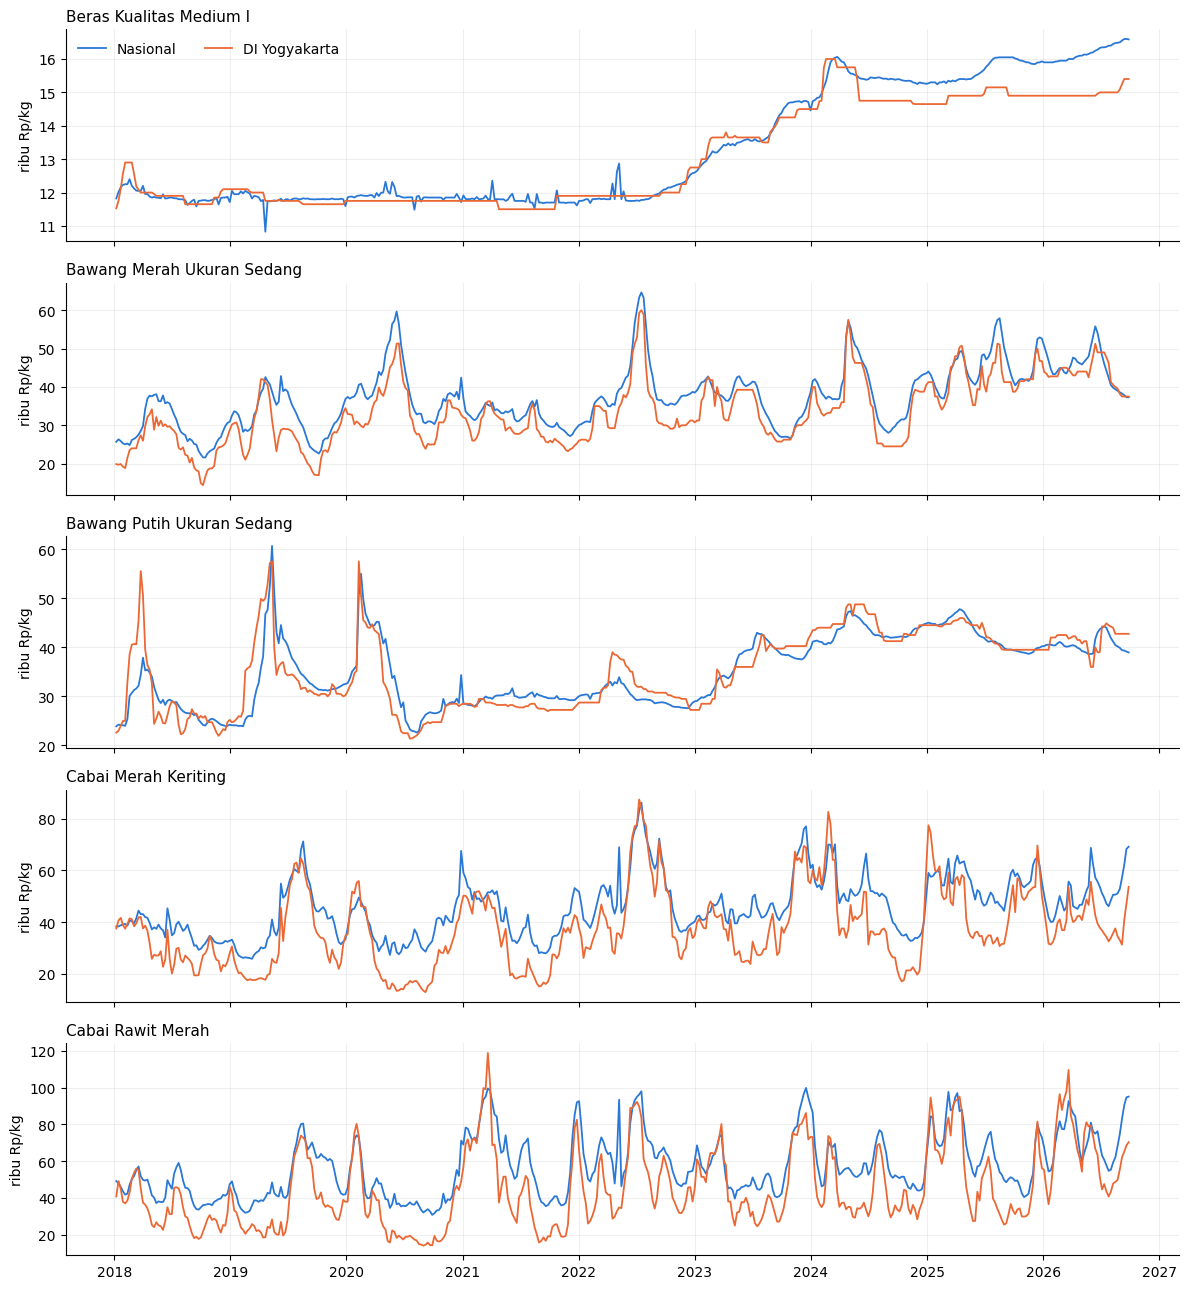

In [3]:
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
for ax, (c, lab) in zip(axes, LABEL.items()):
    for region, color in (("nasional", "#2a78d6"), ("diy", "#eb6834")):
        s = get_series(prices, region, c).resample("W").mean()
        ax.plot(s.index, s / 1000, color=color, lw=1.3, label=cfg["regions"][region]["label"])
    ax.set_title(lab, loc="left", fontsize=11); ax.set_ylabel("ribu Rp/kg")
axes[0].legend(loc="upper left", frameon=False, ncol=2)
plt.tight_layout()

## 2. Volatilitas

Standar deviasi return log harian (dianualisasi) dan persentil perubahan 7 hari — menunjukkan mengapa cabai jauh lebih sulit diprediksi daripada beras.

In [4]:
rows = []
for (r, c), g in prices.groupby(["region", "commodity"]):
    s = np.log(g.set_index("date")["price"])
    d1, d7 = s.diff().dropna(), s.diff(7).dropna()
    rows.append({"wilayah": r, "komoditas": LABEL[c], "vol_tahunan_%": 100 * d1.std() * np.sqrt(365),
                 "perubahan_7h_p5_%": 100 * (np.exp(d7.quantile(.05)) - 1),
                 "perubahan_7h_p95_%": 100 * (np.exp(d7.quantile(.95)) - 1)})
pd.DataFrame(rows).sort_values("vol_tahunan_%", ascending=False)

,wilayah,komoditas,vol_tahunan_%,perubahan_7h_p5_%,perubahan_7h_p95_%
4,diy,Cabai Rawit Merah,105.94,-24.92,35.15
3,diy,Cabai Merah Keriting,89.29,-20.00,26.09
9,nasional,Cabai Rawit Merah,84.01,-13.23,17.32
8,nasional,Cabai Merah Keriting,77.05,-12.29,14.58
5,nasional,Bawang Merah Ukuran Sedang,57.65,-6.50,8.04
0,diy,Bawang Merah Ukuran Sedang,45.51,-11.39,13.68
6,nasional,Bawang Putih Ukuran Sedang,43.78,-3.53,5.07
1,diy,Bawang Putih Ukuran Sedang,33.42,-5.66,7.64
7,nasional,Beras Kualitas Medium I,29.58,-0.64,0.99
2,diy,Beras Kualitas Medium I,5.00,0.00,0.98


## 3. Dekomposisi STL

STL robust pada rata-rata mingguan (periode 52 minggu) untuk setiap komoditas nasional; kekuatan musiman F_s = max(0, 1 − Var(R)/Var(S+R)).

,komoditas,kekuatan_tren,kekuatan_musiman_tahunan
0,Beras Kualitas Medium I,0.97,0.05
1,Bawang Merah Ukuran Sedang,0.62,0.53
2,Bawang Putih Ukuran Sedang,0.76,0.41
3,Cabai Merah Keriting,0.23,0.00
4,Cabai Rawit Merah,0.28,0.19


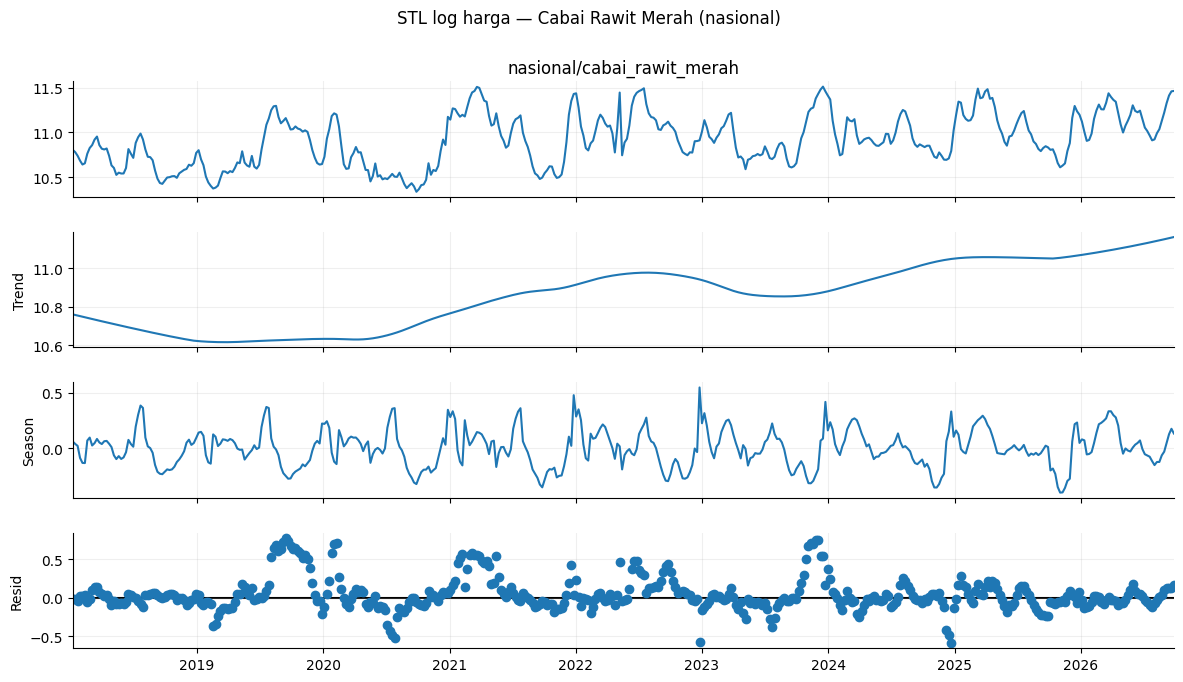

In [5]:
from statsmodels.tsa.seasonal import STL
strength = []
for c, lab in LABEL.items():
    w = np.log(get_series(prices, "nasional", c).resample("W").mean())
    res = STL(w, period=52, robust=True).fit()
    fs = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
    ft = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
    strength.append({"komoditas": lab, "kekuatan_tren": ft, "kekuatan_musiman_tahunan": fs})
    if c == "cabai_rawit_merah":
        fig = res.plot(); fig.set_size_inches(12, 7); fig.suptitle(f"STL log harga — {lab} (nasional)", y=1.01)
pd.DataFrame(strength)

## 4. Musiman mingguan

PIHPS hanya mencatat hari kerja; nilai akhir pekan adalah forward-fill. Rata-rata return per hari kerja (observasi asli saja):

In [6]:
obs = prices[~prices["is_imputed"] & (prices["region"] == "nasional")].copy()
obs = obs.sort_values("date")
obs["ret"] = obs.groupby("commodity")["price"].transform(lambda s: np.log(s).diff())
obs["hari"] = obs["date"].dt.day_name()
(100 * obs.pivot_table(index="hari", columns="commodity", values="ret", aggfunc="mean")).reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]).rename(columns=LABEL)

commodity,Bawang Merah Ukuran Sedang,Bawang Putih Ukuran Sedang,Beras Kualitas Medium I,Cabai Merah Keriting,Cabai Rawit Merah
hari,,,,,
Monday,-0.22,-0.16,0.02,0.34,0.30
Tuesday,0.33,0.12,0.00,0.16,0.16
Wednesday,-0.16,-0.14,-0.01,-0.42,-0.45
Thursday,0.27,0.20,0.03,-0.00,0.19
Friday,-0.10,0.10,0.04,0.05,-0.07


## 5. ACF / PACF

Pada log harga yang di-difference satu kali (cabai rawit merah, nasional).

ADF p-value Beras Kualitas Medium I        level=0.988  diff=0


ADF p-value Bawang Merah Ukuran Sedang     level=0.000  diff=1.17e-19


ADF p-value Bawang Putih Ukuran Sedang     level=0.096  diff=2.15e-30


ADF p-value Cabai Merah Keriting           level=0.003  diff=5.84e-29


ADF p-value Cabai Rawit Merah              level=0.000  diff=4.61e-28


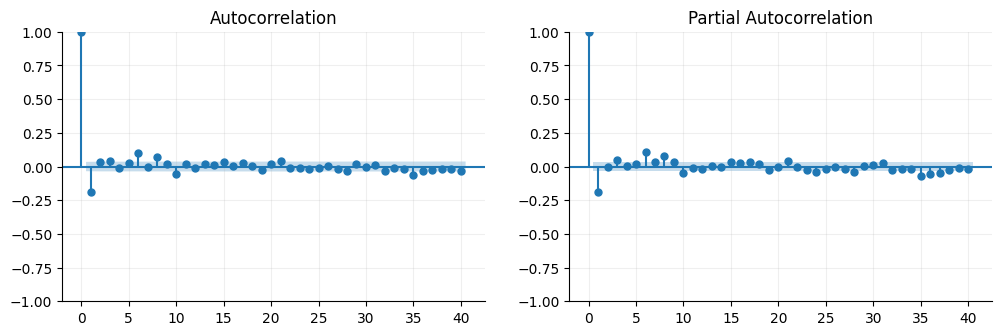

In [7]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
s = np.log(get_series(prices, "nasional", "cabai_rawit_merah"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(s.diff().dropna(), lags=40, ax=ax[0]); plot_pacf(s.diff().dropna(), lags=40, ax=ax[1], method="ywm")
for c, lab in LABEL.items():
    x = np.log(get_series(prices, "nasional", c))
    print(f"ADF p-value {lab:30s} level={adfuller(x)[1]:.3f}  diff={adfuller(x.diff().dropna())[1]:.3g}")

## 6. Efek hari raya

Rata-rata perubahan harga (%) dari H-30 ke jendela sekitar Idulfitri, per komoditas (nasional).

In [8]:
from src.calendar_id import IDULFITRI
rows = []
for c, lab in LABEL.items():
    s = get_series(prices, "nasional", c)
    for y, d in IDULFITRI.items():
        d = pd.Timestamp(d)
        if d - pd.Timedelta(days=30) < s.index[0] or d + pd.Timedelta(days=14) > s.index[-1]:
            continue
        base = s[d - pd.Timedelta(days=30)]
        rows.append({"komoditas": lab, "tahun": y,
                     "H-7_%": 100 * (s[d - pd.Timedelta(days=7)] / base - 1),
                     "H-1_%": 100 * (s[d - pd.Timedelta(days=1)] / base - 1),
                     "H+14_%": 100 * (s[d + pd.Timedelta(days=14)] / base - 1)})
leb = pd.DataFrame(rows)
leb.groupby("komoditas")[["H-7_%", "H-1_%", "H+14_%"]].mean()

,H-7_%,H-1_%,H+14_%
komoditas,,,
Bawang Merah Ukuran Sedang,3.15,7.36,13.62
Bawang Putih Ukuran Sedang,-4.64,-4.91,-3.51
Beras Kualitas Medium I,0.10,2.20,1.66
Cabai Merah Keriting,-13.10,6.96,-9.41
Cabai Rawit Merah,-13.69,2.14,-8.70


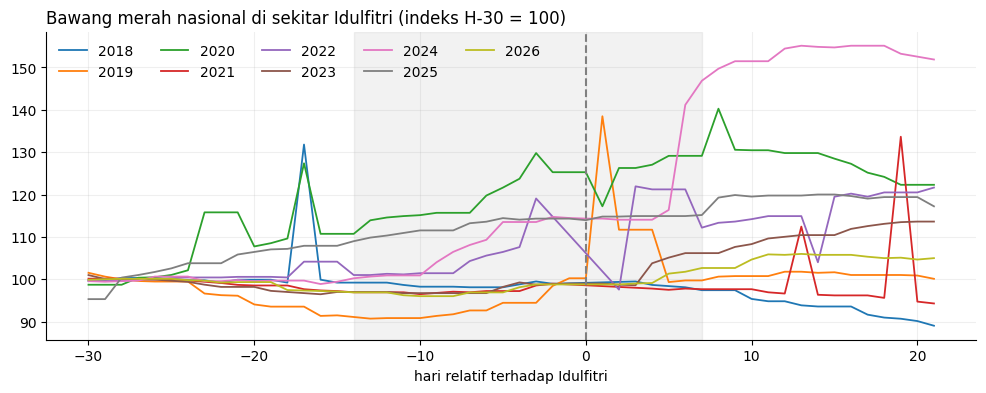

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
s = get_series(prices, "nasional", "bawang_merah")
for i, (y, d) in enumerate(IDULFITRI.items()):
    d = pd.Timestamp(d); w = s.loc[d - pd.Timedelta(days=30): d + pd.Timedelta(days=21)]
    if len(w) < 45: continue
    ax.plot((w.index - d).days, 100 * w / w.iloc[:7].mean(), lw=1.3, label=y)
ax.axvspan(-14, 7, color="gray", alpha=.1); ax.axvline(0, color="gray", ls="--")
ax.set_title("Bawang merah nasional di sekitar Idulfitri (indeks H-30 = 100)", loc="left")
ax.set_xlabel("hari relatif terhadap Idulfitri"); ax.legend(ncol=5, frameon=False)

## Temuan utama

Lihat tabel di atas; ringkasan naratif ada di README bagian *Temuan EDA*. Poin yang mendasari desain model:

1. Cabai (terutama rawit) memiliki volatilitas beberapa kali lipat beras → transformasi log dan interval prediksi wajib.
2. Log harga umumnya tidak stasioner pada level tetapi stasioner setelah differencing → SARIMA dengan d dipilih uji ADF.
3. Terdapat musiman tahunan dan efek hari raya (terutama bawang merah & cabai menjelang Idulfitri) → fitur/regresor H-14 s.d. H+7.
4. Pola mingguan lemah karena akhir pekan tidak diobservasi.